In [51]:
import pandas as pd
import seaborn as sns
from statsmodels.formula.api import ols
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests

In [23]:
pg = pd.read_csv('../Datasets/plant_growth.csv')
pg


,weight,group
0,4.17,ctrl
1,5.58,ctrl
2,5.18,ctrl
3,6.11,ctrl
4,4.50,ctrl
5,4.61,ctrl
6,5.17,ctrl
7,4.53,ctrl
8,5.33,ctrl
9,5.14,ctrl


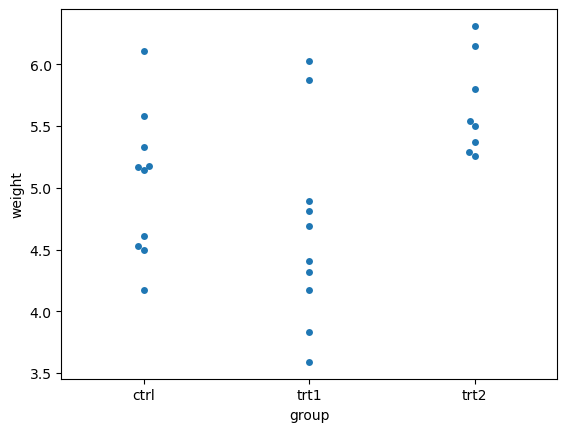

In [24]:
sns.swarmplot(data=pg, x='group', y='weight');

First do an ANOVA "omnibus" test. 

You're checking the compatibility of the data with the null hypothesis that all means are the same.

#### What to do based on the outcome of the test

If the data are compatible with the null (P>0.05) then your analysis stops there. Neither treatment significantly affected plant growth relative to the control

If the data are incompatible with the null (P<0.05) then at least one of the means is significantly difference from the others. You continue the analysis by comparing each treatment to the control.

### ANOVA using anova_oneway()

In [61]:
test = anova_oneway(pg['weight'], pg['group'], use_var='equal')
print(test.df)
print(test.statistic)
print(test.pvalue)

(2.0, 25.0)
5.594501009822159
0.009818440749277929


### ANOVA using a linear model

In [59]:
# the model formula is coded as a string
formula = 'weight ~ group'

# fit the model to the data
fit = ols(formula, pg).fit()

# output summary table of the model fit
fit.summary().tables[0]

Dep. Variable:,weight,R-squared:,0.309
Model:,OLS,Adj. R-squared:,0.254
Method:,Least Squares,F-statistic:,5.595
Date:,"Tue, 13 Oct 2026",Prob (F-statistic):,0.00982
Time:,20:25:50,Log-Likelihood:,-25.078
No. Observations:,28,AIC:,56.16
Df Residuals:,25,BIC:,60.15
Df Model:,2,,
Covariance Type:,nonrobust,,


### At least one of the means is different from the other


So P = 0.01, we continue with the linear model

In this analysis we want the reference level to be the control group as we are comparing each treatment to the control. You may therefore need to change the reference level manually (see [workflow_ground_finch](workflow_ground_finch.ipynb)). Here we don't need to because "control" comes before "treatment" alphabetically.

In [62]:
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,5.0320,0.198,25.374,0.000,4.624,5.440
group[T.trt1],-0.3710,0.280,-1.323,0.198,-0.949,0.207
group[T.trt2],0.6205,0.297,2.086,0.047,0.008,1.233


Control is the reference level. The treatments are compared to it

- `group[T.trt1]` is the mean difference between treatment 1 and control. P = 0.198. So compatible with the null of no difference.

- `group[T.trt2]` is the mean difference between treatment 2 and control. P = 0.047. So incompatible with the null of no difference. But P is close to 0.05, so the evidence is not overwhelming.

But because we did two tests (control vs. trt1 and control vs. trt2) we need to adjust for multiple testing.

Access the raw *P*-values. We don't need the *P*-value for the Intercept (that is just saying that the control plants grew,
 so is of no interest)

In [47]:
p_raw = fit.pvalues.iloc[1:]
p_raw

group[T.trt1]    0.197861
group[T.trt2]    0.047347
dtype: float64

Now we adjust the *P*-values using `scipy.multipletests` like so 

In [2]:
p_holm = multipletests(p_raw, method="holm")[1]
print(p_holm)

NameError: name 'multipletests' is not defined

The *P*-value for treatment 1 vs. control has not changed. But the *P*-value for treatment 2 vs. control is adjusted to 0.09 which is compatible with the null hypothesis of no effect. 

In conclusion, neither treatment significantly affected plant growth.